### Step-1: Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)

### Step-2: Loading the Dataset

In [2]:
df = pd.read_csv("iris.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

Dataset Shape: (150, 5)

First 5 Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


### Step-3: Exploring the Dataset

In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.80

### Step-4: Checking Column Names

In [4]:
print("Column Names:")
print(df.columns.tolist())
print("\nUnique Species:")
print(df['species'].unique())

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Unique Species:
['setosa' 'versicolor' 'virginica']


### Step-5: Checking Missing Values

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


### Step-6: Checking Duplicate Records

In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 3


### Step-7: Selecting All Three Classes for Multiclass Classification

In [7]:
target_column = 'species'
df = df[df[target_column].isin([
    'setosa',
    'versicolor',
    'virginica'
])].copy()

print("Selected Classes:")
print(df[target_column].value_counts())

print("\nDataset Shape:", df.shape)

Selected Classes:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Dataset Shape: (150, 5)


### Step-8: Visualizing the Three-Class Dataset

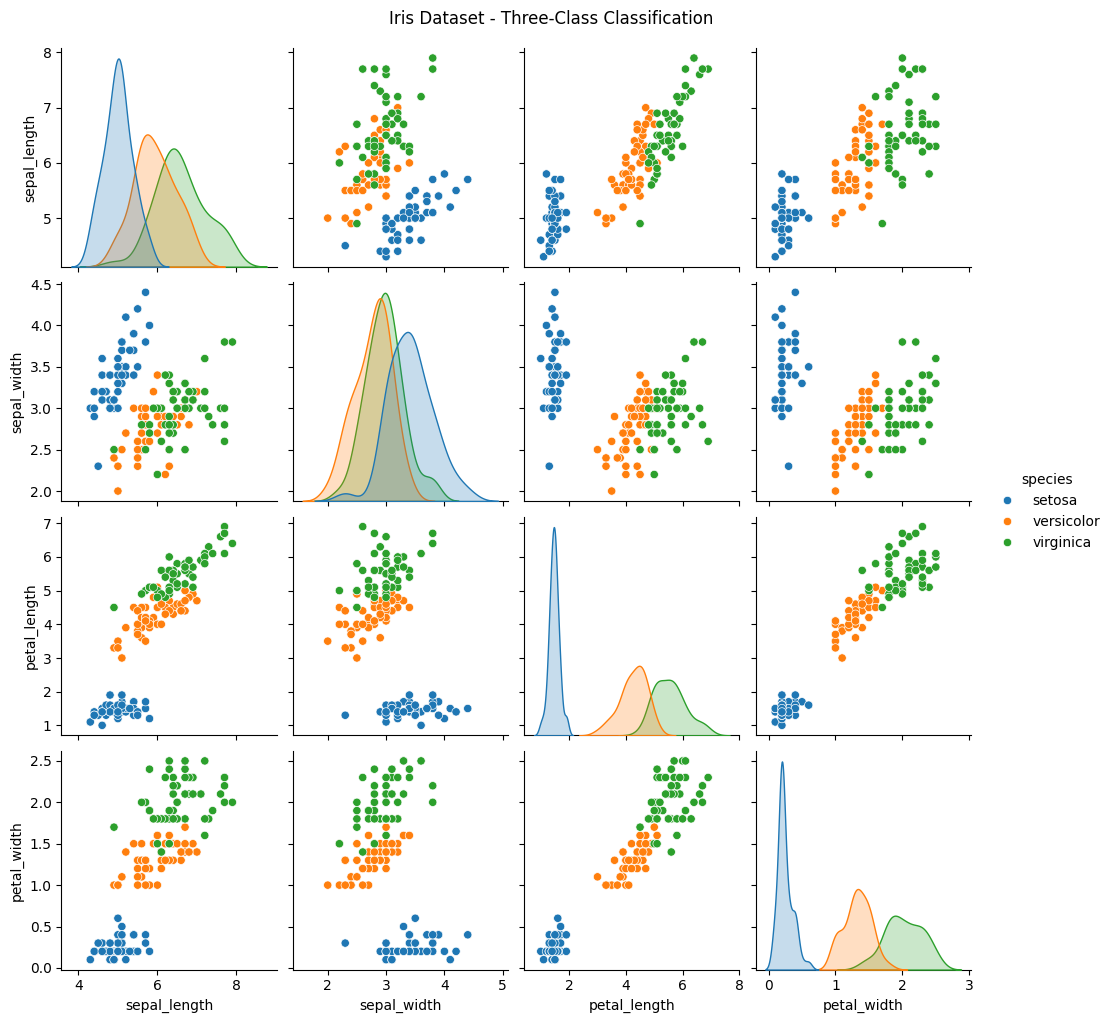

In [8]:
sns.pairplot(df, hue=target_column)
plt.suptitle("Iris Dataset - Three-Class Classification", y=1.02)
plt.show()

### Step-9: Separating Features and Target Variable

In [9]:
X = df.drop(target_column, axis=1)
y = df[target_column]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


### Step-10: Encoding the Target Variable

In [10]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("Encoded Classes:")
print(encoder.classes_)

print("\nEncoded Target Values:")
print(np.unique(y))

Encoded Classes:
['setosa' 'versicolor' 'virginica']

Encoded Target Values:
[0 1 2]


### Step-11: Splitting the Dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


### Step-12: Feature Scaling

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


### Step-13: Building the SVM Model Using Linear Kernel

In [13]:
linear_model = SVC(
    kernel='linear',
    probability=True,
    random_state=42
)

linear_model.fit(X_train_scaled, y_train)

print("Linear SVM Model Trained Successfully!")

Linear SVM Model Trained Successfully!


### Step-14: Making Predictions Using Linear Kernel

In [14]:
y_pred_linear = linear_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred_linear)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


### Step-15: Evaluating the Linear SVM Model (Multiclass)

In [15]:
linear_accuracy = accuracy_score(y_test, y_pred_linear)
linear_precision = precision_score(
    y_test, y_pred_linear, average='weighted', zero_division=0
)
linear_recall = recall_score(
    y_test, y_pred_linear, average='weighted', zero_division=0
)
linear_f1 = f1_score(
    y_test, y_pred_linear, average='weighted', zero_division=0
)

linear_prob = linear_model.predict_proba(X_test_scaled)
linear_auc = roc_auc_score(
    y_test,
    linear_prob,
    multi_class='ovr',
    average='weighted'
)

print("Linear SVM Performance:")
print(f"Accuracy:  {linear_accuracy:.4f}")
print(f"Precision: {linear_precision:.4f} (weighted)")
print(f"Recall:    {linear_recall:.4f} (weighted)")
print(f"F1 Score:  {linear_f1:.4f} (weighted)")
print(f"AUC Score: {linear_auc:.4f} (weighted OvR)")

Linear SVM Performance:
Accuracy:  1.0000
Precision: 1.0000 (weighted)
Recall:    1.0000 (weighted)
F1 Score:  1.0000 (weighted)
AUC Score: 1.0000 (weighted OvR)


### Step-16: Building the SVM Model Using RBF Kernel

In [16]:
rbf_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

rbf_model.fit(X_train_scaled, y_train)

print("RBF SVM Model Trained Successfully!")

RBF SVM Model Trained Successfully!


### Step-17: Making Predictions Using RBF Kernel

In [17]:
y_pred_rbf = rbf_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred_rbf)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


### Step-19: Evaluating the RBF SVM Model (Multiclass)

In [18]:
rbf_accuracy = accuracy_score(y_test, y_pred_rbf)
rbf_precision = precision_score(
    y_test, y_pred_rbf, average='weighted', zero_division=0
)
rbf_recall = recall_score(
    y_test, y_pred_rbf, average='weighted', zero_division=0
)
rbf_f1 = f1_score(
    y_test, y_pred_rbf, average='weighted', zero_division=0
)

rbf_prob = rbf_model.predict_proba(X_test_scaled)
rbf_auc = roc_auc_score(
    y_test,
    rbf_prob,
    multi_class='ovr',
    average='weighted'
)

print("RBF SVM Performance:")
print(f"Accuracy:  {rbf_accuracy:.4f}")
print(f"Precision: {rbf_precision:.4f} (weighted)")
print(f"Recall:    {rbf_recall:.4f} (weighted)")
print(f"F1 Score:  {rbf_f1:.4f} (weighted)")
print(f"AUC Score: {rbf_auc:.4f} (weighted OvR)")

RBF SVM Performance:
Accuracy:  0.9667
Precision: 0.9697 (weighted)
Recall:    0.9667 (weighted)
F1 Score:  0.9666 (weighted)
AUC Score: 0.9967 (weighted OvR)


### Step-20: Comparing Linear and RBF Kernels

In [19]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'],
    'Linear Kernel': [
        linear_accuracy,
        linear_precision,
        linear_recall,
        linear_f1,
        linear_auc
    ],
    'RBF Kernel': [
        rbf_accuracy,
        rbf_precision,
        rbf_recall,
        rbf_f1,
        rbf_auc
    ]
})

print(comparison)

      Metric  Linear Kernel  RBF Kernel
0   Accuracy            1.0    0.966667
1  Precision            1.0    0.969697
2     Recall            1.0    0.966667
3   F1 Score            1.0    0.966583
4        AUC            1.0    0.996667


### Step-20: Visualizing Kernel Performance

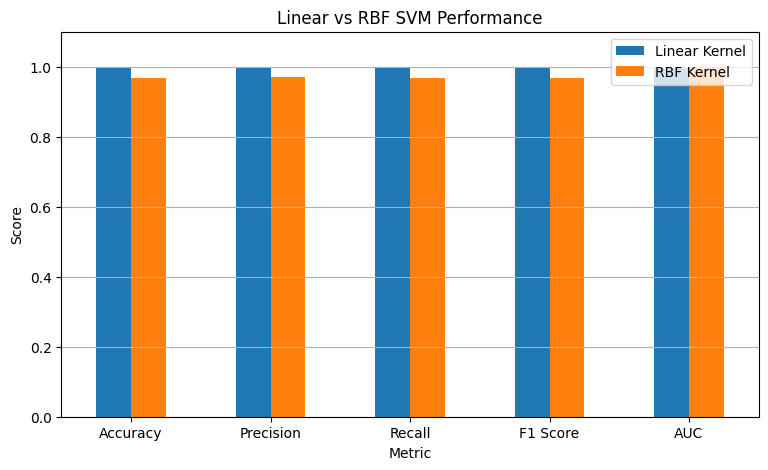

In [20]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Linear vs RBF SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()

### Step-21: Visualizing Three-Class Decision Boundaries (Two Features)

In [21]:
X_2d = df[['sepal_length', 'sepal_width']]

print("Features used for 2D visualization:", X_2d.columns.tolist())

Features used for 2D visualization: ['sepal_length', 'sepal_width']


In [22]:
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

linear_2d = SVC(kernel='linear', decision_function_shape='ovr')
rbf_2d = SVC(kernel='rbf', decision_function_shape='ovr')

linear_2d.fit(X_train_2d_scaled, y_train_2d)
rbf_2d.fit(X_train_2d_scaled, y_train_2d)

print("2D Linear and RBF SVM models trained for visualization.")

2D Linear and RBF SVM models trained for visualization.


In [23]:
x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1
y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

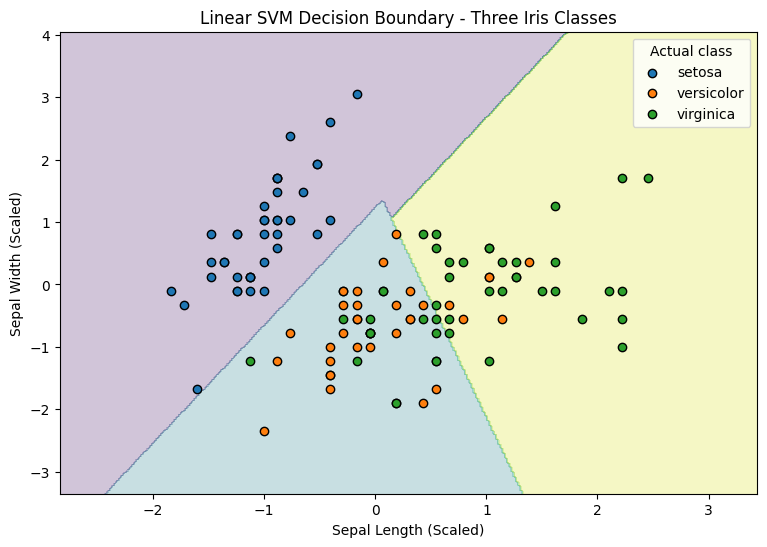

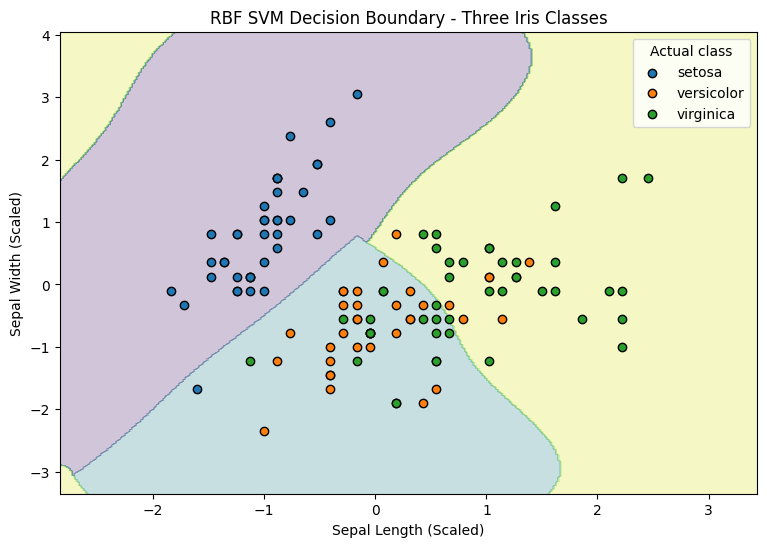

In [24]:
Z_linear = linear_2d.predict(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_linear, alpha=0.25, cmap='viridis')

for class_id, class_name in enumerate(encoder.classes_):
    mask = (y_train_2d == class_id)
    plt.scatter(
        X_train_2d_scaled[mask, 0],
        X_train_2d_scaled[mask, 1],
        label=class_name,
        edgecolors='black'
    )

plt.title("Linear SVM Decision Boundary - Three Iris Classes")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.legend(title="Actual class")
plt.show()

Z_rbf = rbf_2d.predict(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_rbf, alpha=0.25, cmap='viridis')

for class_id, class_name in enumerate(encoder.classes_):
    mask = (y_train_2d == class_id)
    plt.scatter(
        X_train_2d_scaled[mask, 0],
        X_train_2d_scaled[mask, 1],
        label=class_name,
        edgecolors='black'
    )

plt.title("RBF SVM Decision Boundary - Three Iris Classes")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.legend(title="Actual class")
plt.show()

### Step-22: Generating Classification Reports for Linear and RBF SVM

In [25]:
print("Linear SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

print("\nRBF SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_rbf,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Linear SVM Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


RBF SVM Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Step-23: Visualizing Confusion Matrices for Both SVM Models

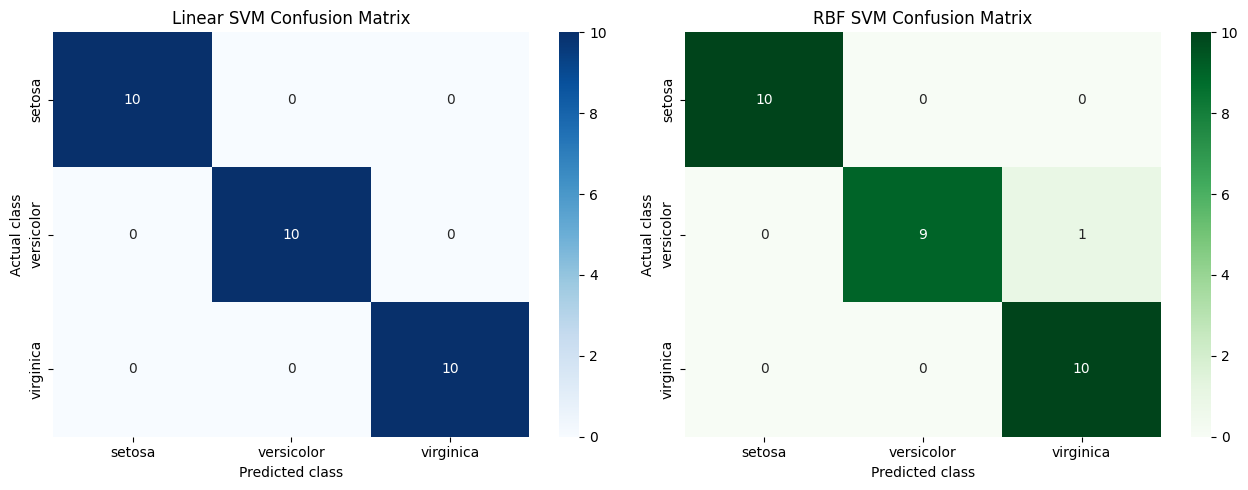

In [26]:
class_labels = encoder.classes_
class_ids = np.arange(len(class_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_linear = confusion_matrix(y_test, y_pred_linear, labels=class_ids)
cm_rbf = confusion_matrix(y_test, y_pred_rbf, labels=class_ids)

sns.heatmap(
    cm_linear,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[0]
)
axes[0].set_title("Linear SVM Confusion Matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1]
)
axes[1].set_title("RBF SVM Confusion Matrix")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

plt.tight_layout()
plt.show()

### Step-24: Plotting Multiclass ROC Curves Using One-vs-Rest (OvR)

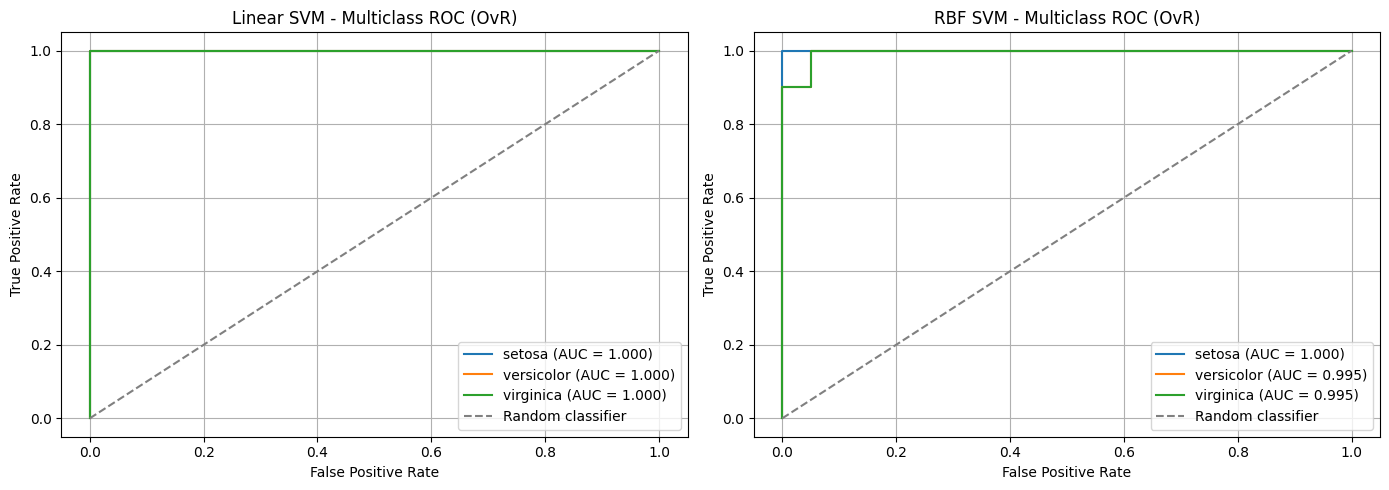

In [27]:
y_test_bin = label_binarize(y_test, classes=class_ids)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for class_id, class_name in enumerate(class_labels):
    fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], linear_prob[:, class_id])
    class_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f'{class_name} (AUC = {class_auc:.3f})')

    fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], rbf_prob[:, class_id])
    class_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, label=f'{class_name} (AUC = {class_auc:.3f})')

for ax, title in zip(
    axes,
    ["Linear SVM - Multiclass ROC (OvR)", "RBF SVM - Multiclass ROC (OvR)"]
):
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()